This is where the ML stuff will go twin

In [1]:
print('hi')

hi


In [18]:
import pandas as pd

final_df = pd.read_csv('Datas/final_data.csv')

# Investigate the sussy PurpleAir Sensors

suspicious = (
    final_df[
        (final_df["source"] == "PURPLEAIR") &
        (final_df["pm25"] > 1000)
    ]
    .groupby("sensor_key")
    .agg(
        extreme_months=("pm25", "size"),
        max_pm25=("pm25", "max")
    )
    .sort_values("extreme_months", ascending=False)
)

print(suspicious)

final_df = final_df[final_df["pm25"] < 1000]
final_df['pm25'].max()


Empty DataFrame
Columns: [extreme_months, max_pm25]
Index: []


np.float64(115.45)

In [22]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score
from xgboost import XGBRegressor
import numpy as np

# Our wonderful features
# May change in the feature to capture seasonal differences
features = [
    "month",
    "traffic_Vol_sum",
    "boiler_count",
    "buildings_Fuel Oil #2 Use (kBtu)_sum",
    "buildings_Fuel Oil #4 Use (kBtu)_sum",
    "buildings_Natural Gas Use (kBtu)_sum",
    "buildings_Direct GHG Emissions (Metric Tons CO2e)_sum",
    "buildings_Property GFA - Calculated (Buildings) (ft²)_sum",
    "buildings_Site EUI (kBtu/ft²)_mean",
    "building_permit_count",
    "tree_count"
]
df = final_df.dropna(subset=["pm25"]).copy()

# Model without traffic
features_no_traffic = [
    col for col in features
    if col != "traffic_Vol_sum"
]

X = df[features_no_traffic]
y = df["pm25"]

# X = df[features]
# y = df["pm25"]

# Keep all observations from a sensor together
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=df["sensor_key"])
)

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

# Linear regression with missing-value imputation
linear = make_pipeline(
    SimpleImputer(strategy="median"),
    LinearRegression()
)

# XGBoost
xgb = XGBRegressor(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    random_state=42
)

for name, model in [
    ("Linear Regression", linear),
    ("XGBoost", xgb)
]:
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    print(name)
    print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
    print("R²:", r2_score(y_test, predictions))

Linear Regression
RMSE: 3.674938052142377
R²: -0.11742712547468348
XGBoost
RMSE: 4.275336617164946
R²: -0.5123760567921751


In [ ]:

# Our wonderful features
# May change in the feature to capture seasonal differences
features = [
    "month"
    
]
df = final_df.dropna(subset=["pm25"]).copy()

X = df[features]
y = df["pm25"]

# Keep all observations from a sensor together
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=df["sensor_key"])
)

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

# Linear regression with missing-value imputation
linear = make_pipeline(
    SimpleImputer(strategy="median"),
    LinearRegression()
)

# XGBoost
xgb = XGBRegressor(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    random_state=42
)

for name, model in [
    ("Linear Regression", linear),
    ("XGBoost", xgb)
]:
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    print(name)
    print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
    print("R²:", r2_score(y_test, predictions))

TypeError: '<' not supported between instances of 'int' and 'str'

In [32]:
df_train = df.iloc[train_idx].copy()

extreme = (
    df_train[df_train["pm25"] > 30]
    .sort_values("pm25", ascending=False)
)

extreme[
    ["sensor_key", "source", "year", "month", "pm25"]
].head(20)


mask = y_train <= 30

X_train_filtered = X_train.loc[mask]
y_train_filtered = y_train.loc[mask]

# Refit models
linear.fit(X_train_filtered, y_train_filtered)
xgb.fit(X_train_filtered, y_train_filtered)

for name, model in [
    ("Linear Regression", linear),
    ("XGBoost", xgb)
]:
    predictions = model.predict(X_test)

    print(name)
    print(
        "Testing RMSE:",
        np.sqrt(mean_squared_error(y_test, predictions))
    )
    print("Testing R²:", r2_score(y_test, predictions))


print("Linear training R²:",
      r2_score(y_train, linear.predict(X_train)))

print("XGBoost training R²:",
      r2_score(y_train, xgb.predict(X_train)))

print(len(final_df[final_df['pm25'] <= 30]))


Linear Regression
Testing RMSE: 3.656332992089415
Testing R²: -0.10614139909725462
XGBoost
Testing RMSE: 3.1395754183236306
Testing R²: 0.18443044659658814
Linear training R²: 0.009305359152888437
XGBoost training R²: 0.3901051440688722
3183


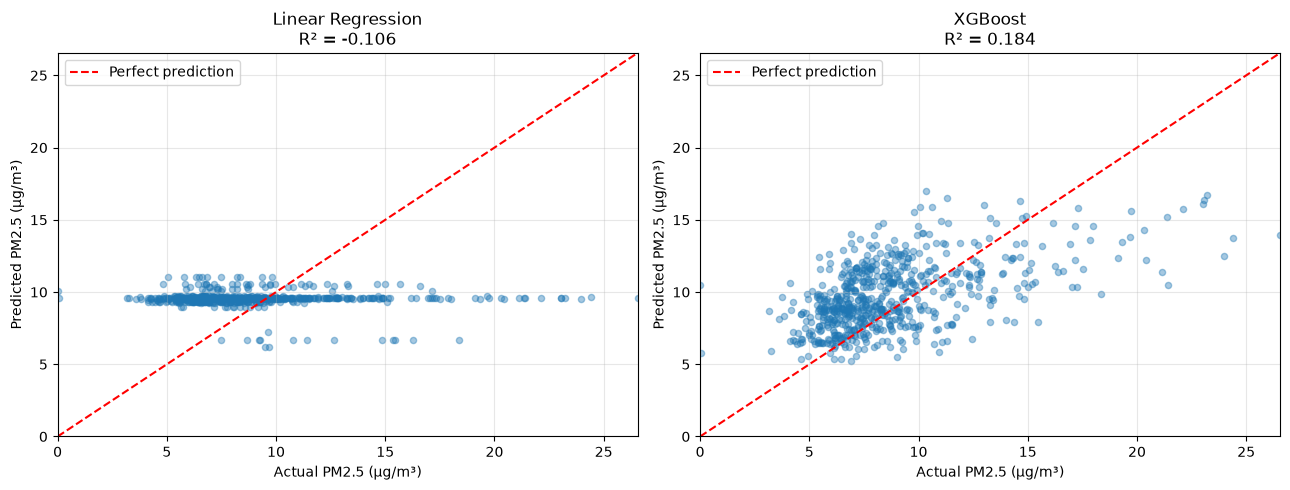

In [33]:
# Scatterplot of Predicted vs. Actual

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import r2_score

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

models = [
    ("Linear Regression", linear),
    ("XGBoost", xgb)
]

for ax, (name, model) in zip(axes, models):
    predictions = model.predict(X_test)

    # Scatterplot of actual vs predicted PM2.5
    ax.scatter(
        y_test,
        predictions,
        alpha=0.4,
        s=20
    )

    # Perfect prediction line: y = x
    limits = [
        min(y_test.min(), predictions.min()),
        max(y_test.max(), predictions.max())
    ]

    ax.plot(limits, limits, "r--", label="Perfect prediction")

    ax.set_xlim(limits)
    ax.set_ylim(limits)

    ax.set_xlabel("Actual PM2.5 (µg/m³)")
    ax.set_ylabel("Predicted PM2.5 (µg/m³)")
    ax.set_title(f"{name}\nR² = {r2_score(y_test, predictions):.3f}")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

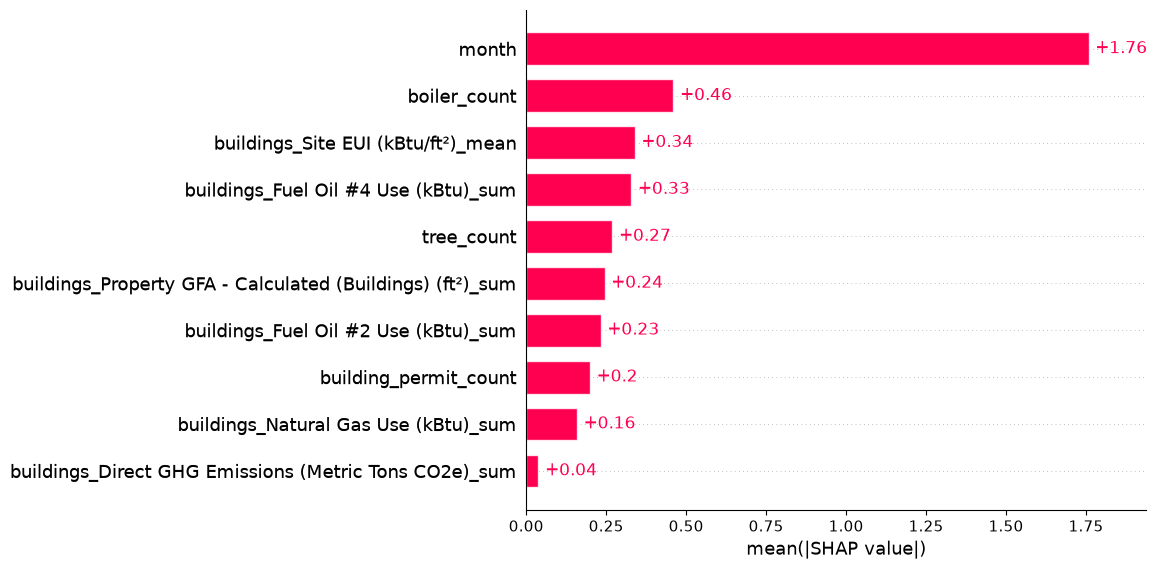

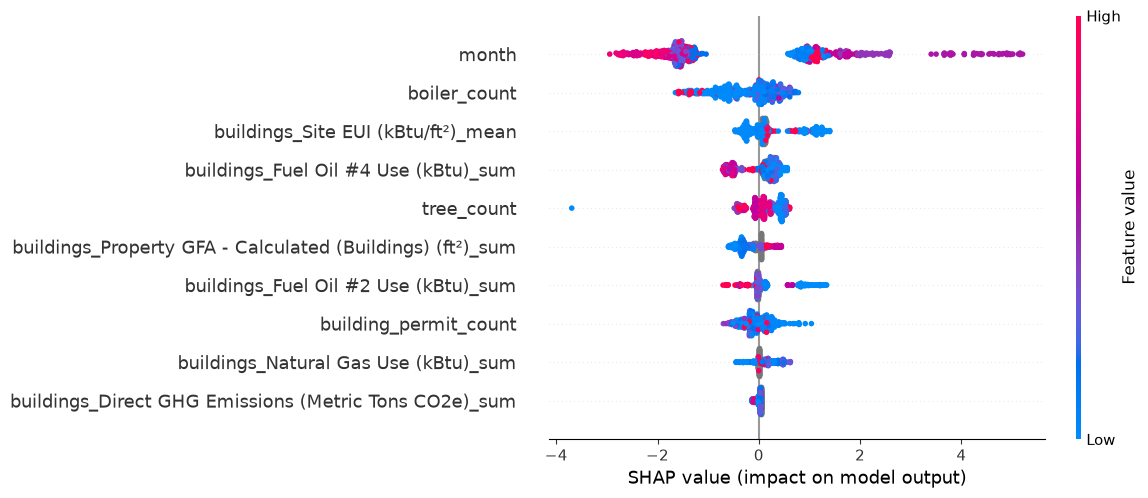

                                                  feature  mean_abs_shap
                       buildings_Site EUI (kBtu/ft²)_mean       0.166312
                     buildings_Fuel Oil #2 Use (kBtu)_sum       0.142741
                                               tree_count       0.142433
                     buildings_Natural Gas Use (kBtu)_sum       0.118256
                     buildings_Fuel Oil #4 Use (kBtu)_sum       0.022712
    buildings_Direct GHG Emissions (Metric Tons CO2e)_sum       0.006208
                                                    month       0.005093
                                    building_permit_count      -0.030020
buildings_Property GFA - Calculated (Buildings) (ft²)_sum      -0.164268
                                             boiler_count      -0.222576


In [35]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Explain the trained XGBoost model
explainer = shap.TreeExplainer(xgb)
shap_values = explainer(X_test)

# 2. Global feature importance
shap.plots.bar(shap_values, max_display=10)

# 3. Feature impact and direction
shap.plots.beeswarm(shap_values, max_display=10)

# 4. Numerical importance ranking
importance = pd.DataFrame({
    "feature": X_test.columns,
    "mean_abs_shap": shap_values.values.mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

print(importance.to_string(index=False))

In [10]:
print(df["pm25"].describe(
    percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]
))

print("Maximum PM2.5:", df["pm25"].max())
print("Minimum PM2.5:", df["pm25"].min())

df.nlargest(
    15, "pm25"
)[["sensor_key", "year", "month", "pm25"]]

df[df['pm25'] > 1000]

count    3588.000000
mean       52.225477
std       310.750648
min         0.000000
1%          1.830300
5%          4.334822
50%         8.511256
95%        23.894320
99%      1672.980645
max      4172.483333
Name: pm25, dtype: float64
Maximum PM2.5: 4172.483333333334
Minimum PM2.5: 0.0


,source,sensor_id,latitude,longitude,year,month,pm25,sensor_key,geometry,sensor_ym,traffic_Vol_sum,boiler_count,buildings_Fuel Oil #2 Use (kBtu)_sum,buildings_Fuel Oil #4 Use (kBtu)_sum,buildings_Natural Gas Use (kBtu)_sum,buildings_Direct GHG Emissions (Metric Tons CO2e)_sum,buildings_Property GFA - Calculated (Buildings) (ft²)_sum,buildings_Site EUI (kBtu/ft²)_mean,building_permit_count,tree_count
1998,PURPLEAIR,87557,40.778080,-73.914920,2022,1,2041.380645,PURPLEAIR_87557,POINT (591563.0988641204 4514688.627151966),24265,NaN,45,181543472.1,57622949.3,584235583.6,48842.8,14790046.0,87.691935,520,6201
2004,PURPLEAIR,87557,40.778080,-73.914920,2022,2,1926.917857,PURPLEAIR_87557,POINT (591563.0988641204 4514688.627151966),24266,NaN,43,181543472.1,57622949.3,584235583.6,48842.8,14790046.0,87.691935,510,6201
2010,PURPLEAIR,87557,40.778080,-73.914920,2022,3,1793.074194,PURPLEAIR_87557,POINT (591563.0988641204 4514688.627151966),24267,NaN,44,181543472.1,57622949.3,584235583.6,48842.8,14790046.0,87.691935,537,6201
2016,PURPLEAIR,87557,40.778080,-73.914920,2022,4,1693.063333,PURPLEAIR_87557,POINT (591563.0988641204 4514688.627151966),24268,NaN,43,181543472.1,57622949.3,584235583.6,48842.8,14790046.0,87.691935,511,6201
2022,PURPLEAIR,87557,40.778080,-73.914920,2022,5,1672.938710,PURPLEAIR_87557,POINT (591563.0988641204 4514688.627151966),24269,NaN,41,181543472.1,57622949.3,584235583.6,48842.8,14790046.0,87.691935,484,6201
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3274,PURPLEAIR,208355,40.865160,-73.931590,2025,6,1759.520000,PURPLEAIR_208355,POINT (590038.548910799 4524338.013001488),24306,NaN,422,NaN,NaN,NaN,NaN,NaN,NaN,85,3776
3276,PURPLEAIR,208355,40.865160,-73.931590,2025,7,1525.609091,PURPLEAIR_208355,POINT (590038.548910799 4524338.013001488),24307,NaN,439,NaN,NaN,NaN,NaN,NaN,NaN,87,3776
3315,PURPLEAIR,238575,40.693375,-73.992540,2026,11,1245.215385,PURPLEAIR_238575,POINT (585121.0331612307 4505207.653654142),24323,NaN,796,NaN,NaN,NaN,NaN,NaN,NaN,184,7581
3520,PURPLEAIR,293913,40.744663,-73.883766,2026,6,1674.777778,PURPLEAIR_293913,POINT (594239.2299041955 4511012.060459704),24318,NaN,709,NaN,NaN,NaN,NaN,NaN,NaN,89,10569
